# Five perspectives, one evidence inventory

**Objective:** Translate agency readings into answerable questions and identify evidence that this package does not contain.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

CDC links human, animal and environmental work; WHO emphasizes coordinated action across sectors. NOAA helps frame aquatic conditions and coastal connections. USGS brings environmental measurement and pathways; NASA supports the interpretation of Earth observations. These are complementary prompts, not five interchangeable sources of health outcomes.

This package includes surface reflectance, a derived surface temperature and population. It includes no diagnoses, animal surveillance, water chemistry, personal exposure, mobility or health-service records. The NASA presentation supplied during planning is **excluded** from all lesson material.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=01_agency_questions.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
questions = {
    "CDC": ("Could an exposure pathway be investigated?", "diagnoses, contact and animal surveillance"),
    "WHO": ("Who needs a voice in a shared decision?", "community priorities and service access"),
    "NOAA": ("What would establish a water-quality concern?", "in-situ chemistry and ecological observations"),
    "USGS": ("What conditions can we locate?", "field validation and repeated observations"),
    "NASA": ("Does this sensor fit the question?", "temporal coverage and measurement uncertainty")}
for agency, (question, missing) in questions.items():
    print(f"{agency}: {question} Missing: {missing}.")
assert len(questions) == 5

CDC: Could an exposure pathway be investigated? Missing: diagnoses, contact and animal surveillance.
WHO: Who needs a voice in a shared decision? Missing: community priorities and service access.
NOAA: What would establish a water-quality concern? Missing: in-situ chemistry and ecological observations.
USGS: What conditions can we locate? Missing: field validation and repeated observations.
NASA: Does this sensor fit the question? Missing: temporal coverage and measurement uncertainty.


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

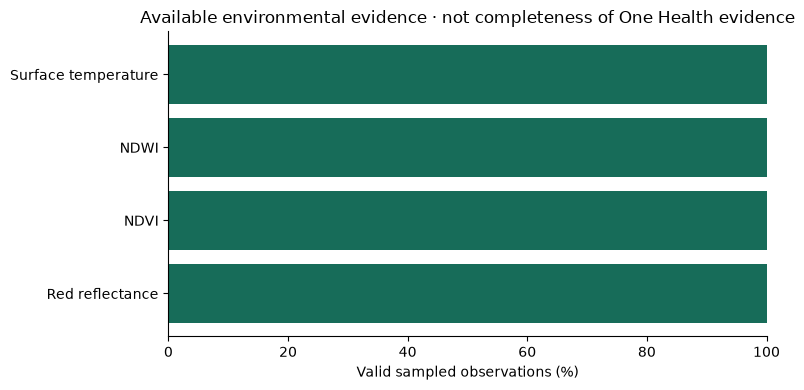

In [3]:
available = [len(values(k)) / len(data) * 100 for k in ("red", "ndvi", "ndwi", "temperature_c")]
plt.barh(["Red reflectance", "NDVI", "NDWI", "Surface temperature"], available, color="#176c59")
plt.xlim(0, 100); plt.xlabel("Valid sampled observations (%)")
plt.title("Available environmental evidence · not completeness of One Health evidence")
plt.tight_layout(); plt.show()

## Interpret and extend

Choose one agency question and write an observation plan with a population, place, time, measurement unit and missing partner. A high valid-pixel percentage does not mean the question is answered.

## Sources and attribution

- [CDC, About One Health](https://www.cdc.gov/one-health/about/index.html).
- [WHO, One Health](https://www.who.int/health-topics/one-health).
- [NOAA National Ocean Service, Are all algal blooms harmful?](https://oceanservice.noaa.gov/facts/habharm.html).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [NASA, Landsat 9](https://science.nasa.gov/mission/landsat-9/).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.